# 02 · Modelagem: o que dá para prever com estes dados?

O README propõe regressão linear para prever a taxa de criminalidade. Aqui testamos isso de forma honesta:

- **Validação cruzada leave-one-out (LOOCV):** com 27 linhas, um split treino/teste único depende demais de sorte. No LOOCV, cada capital é prevista por um modelo que nunca a viu.
- **Baseline:** prever a média. Um modelo só tem valor se errar menos que isso.
- **Binomial negativa:** homicídios são *contagens*; o modelo adequado é um GLM de contagem com `offset = log(população)`, em vez de regressão linear sobre a taxa.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote do projeto sem instalação (ou use `pip install -e .`)
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from crime_analysis import config
from crime_analysis.data import load_processed
from crime_analysis.model import compare_models, fit_full, loocv, MODELOS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)
CORES_REGIAO = {"N": "#2a9d8f", "NE": "#e76f51", "CO": "#e9c46a", "SE": "#264653", "S": "#8ab17d"}

df = load_processed()  # caminho absoluto via config: funciona de qualquer pasta
df.head()

,municipio,uf,regiao,populacao,homicidios_registrados,homicidios_ocultos,homicidios_estimados,taxa_informada_100k,taxa_calculada_100k,taxa_inconsistente,pct_ocultos,log_populacao
0,Porto Velho,RO,N,550463,468,14,482,54.9,87.56,True,2.90,13.22
1,Salvador,BA,NE,2417678,1568,37,1605,66.4,66.39,False,2.31,14.70
2,Recife,PE,NE,1690028,1003,13,1016,45.3,60.12,True,1.28,14.34
3,Manaus,AM,N,2063683,1130,19,1149,55.7,55.68,False,1.65,14.54
4,Macapá,AP,N,442932,241,3,244,55.8,55.09,True,1.23,13.00


## 1. Comparação de modelos (LOOCV)

In [2]:
resultados = compare_models(df)
resultados

,MAE,RMSE,R² (LOOCV)
modelo,,,
Baseline (média),15.04,19.59,-0.08
OLS: taxa ~ log(pop),15.67,20.12,-0.14
OLS: taxa ~ log(pop) + região,13.33,17.07,0.18
Bin. Negativa: homicídios ~ log(pop) + região,13.39,17.04,0.18


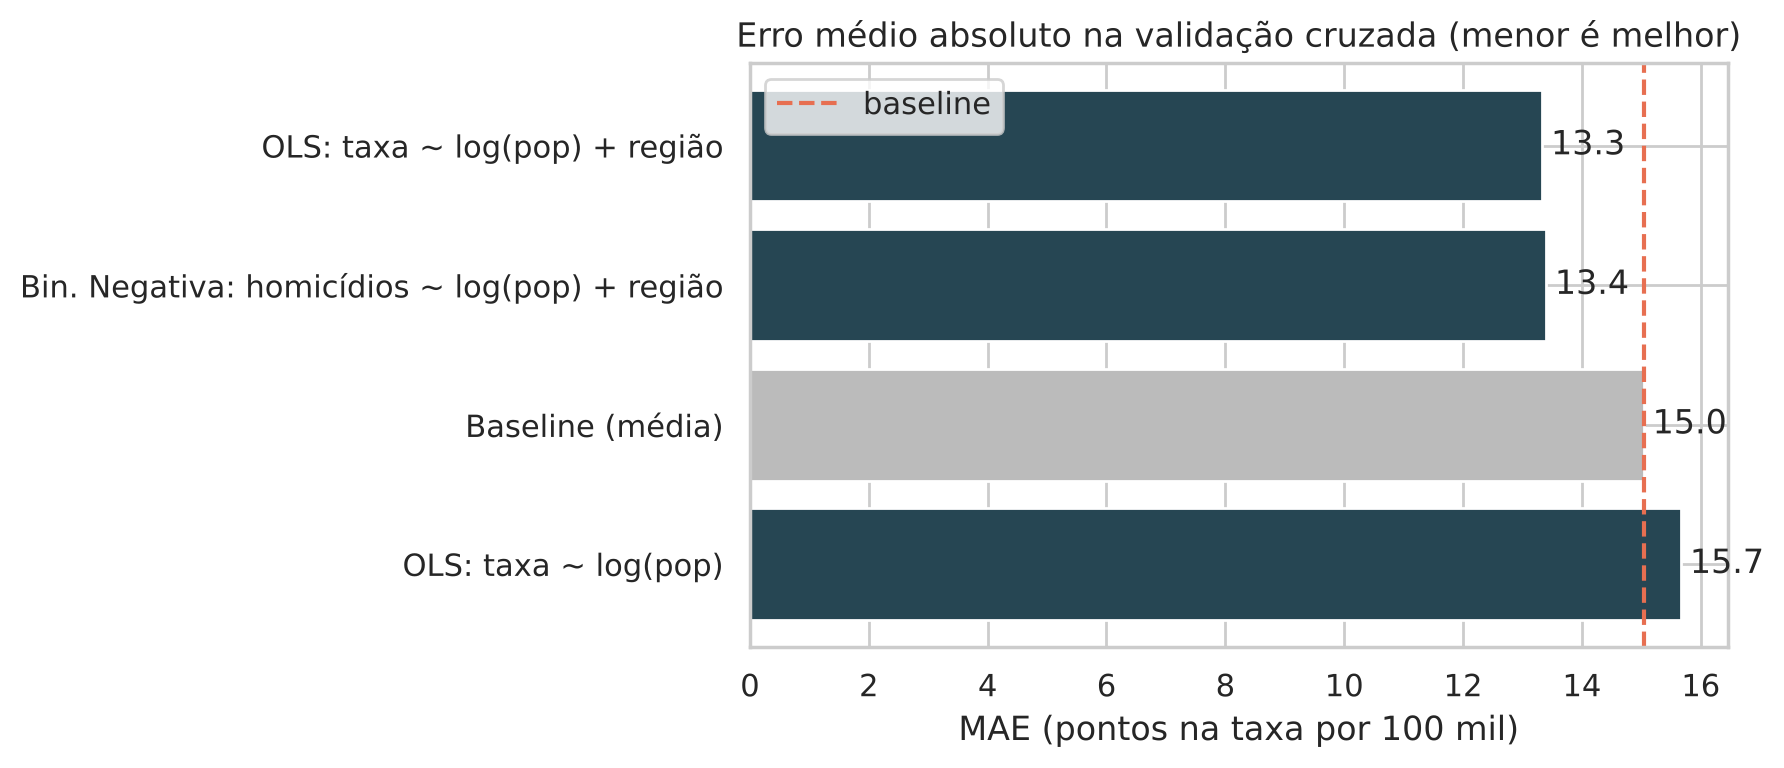

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
r = resultados.sort_values("MAE", ascending=False)
cores = ["#bbbbbb" if "Baseline" in i else "#264653" for i in r.index]
ax.barh(r.index, r["MAE"], color=cores)
ax.axvline(resultados.loc["Baseline (média)", "MAE"], c="#e76f51", ls="--", label="baseline")
for i, v in enumerate(r["MAE"]):
    ax.text(v + 0.15, i, f"{v:.1f}", va="center")
ax.set(title="Erro médio absoluto na validação cruzada (menor é melhor)", xlabel="MAE (pontos na taxa por 100 mil)")
ax.legend(); plt.tight_layout(); plt.show()

**Leitura:**
- **Só população é pior que a média** (R² negativo). A hipótese implícita no notebook original não se sustenta.
- **Adicionar região melhora** o erro em cerca de 1,7 ponto e leva o R² fora da amostra a ~0,18. É ganho real, mas modesto: o modelo ainda erra em média ~13 homicídios por 100 mil.
- **OLS e binomial negativa empatam aqui.** Com mais dados (vários anos, municípios não-capitais) a binomial negativa tende a ser mais confiável, porque respeita a natureza de contagem e dá menos peso a cidades pequenas com taxas voláteis.

## 2. Interpretando o melhor modelo

In [4]:
nb = fit_full(df, "Bin. Negativa: homicídios ~ log(pop) + região")
coef = pd.DataFrame({
    "razão de taxas": np.exp(nb.params),
    "IC 95% inf": np.exp(nb.conf_int()[0]),
    "IC 95% sup": np.exp(nb.conf_int()[1]),
    "p-valor": nb.pvalues,
}).drop(index="Intercept")
coef

,razão de taxas,IC 95% inf,IC 95% sup,p-valor
C(regiao)[T.N],3.15,1.69,5.88,3.03e-04
C(regiao)[T.NE],2.95,1.67,5.23,2.04e-04
C(regiao)[T.S],1.26,0.61,2.61,5.35e-01
C(regiao)[T.SE],1.41,0.70,2.85,3.38e-01
log_populacao,1.00,0.78,1.28,9.90e-01


**Como ler:** a categoria de referência é a região CO. Uma razão de taxas de 3 em `C(regiao)[T.N]` significa que capitais do Norte têm, em média, cerca de 3 vezes a taxa do Centro-Oeste para a mesma população; o Nordeste fica perto disso. Sul e Sudeste não diferem do CO de forma estatisticamente significativa, e `log_populacao` tem razão ≈ 1 (sem efeito).
Os intervalos de confiança são largos — reflexo direto das 27 observações e da Brasília possivelmente subestimada puxando o CO para baixo.

## 3. Previsto × observado

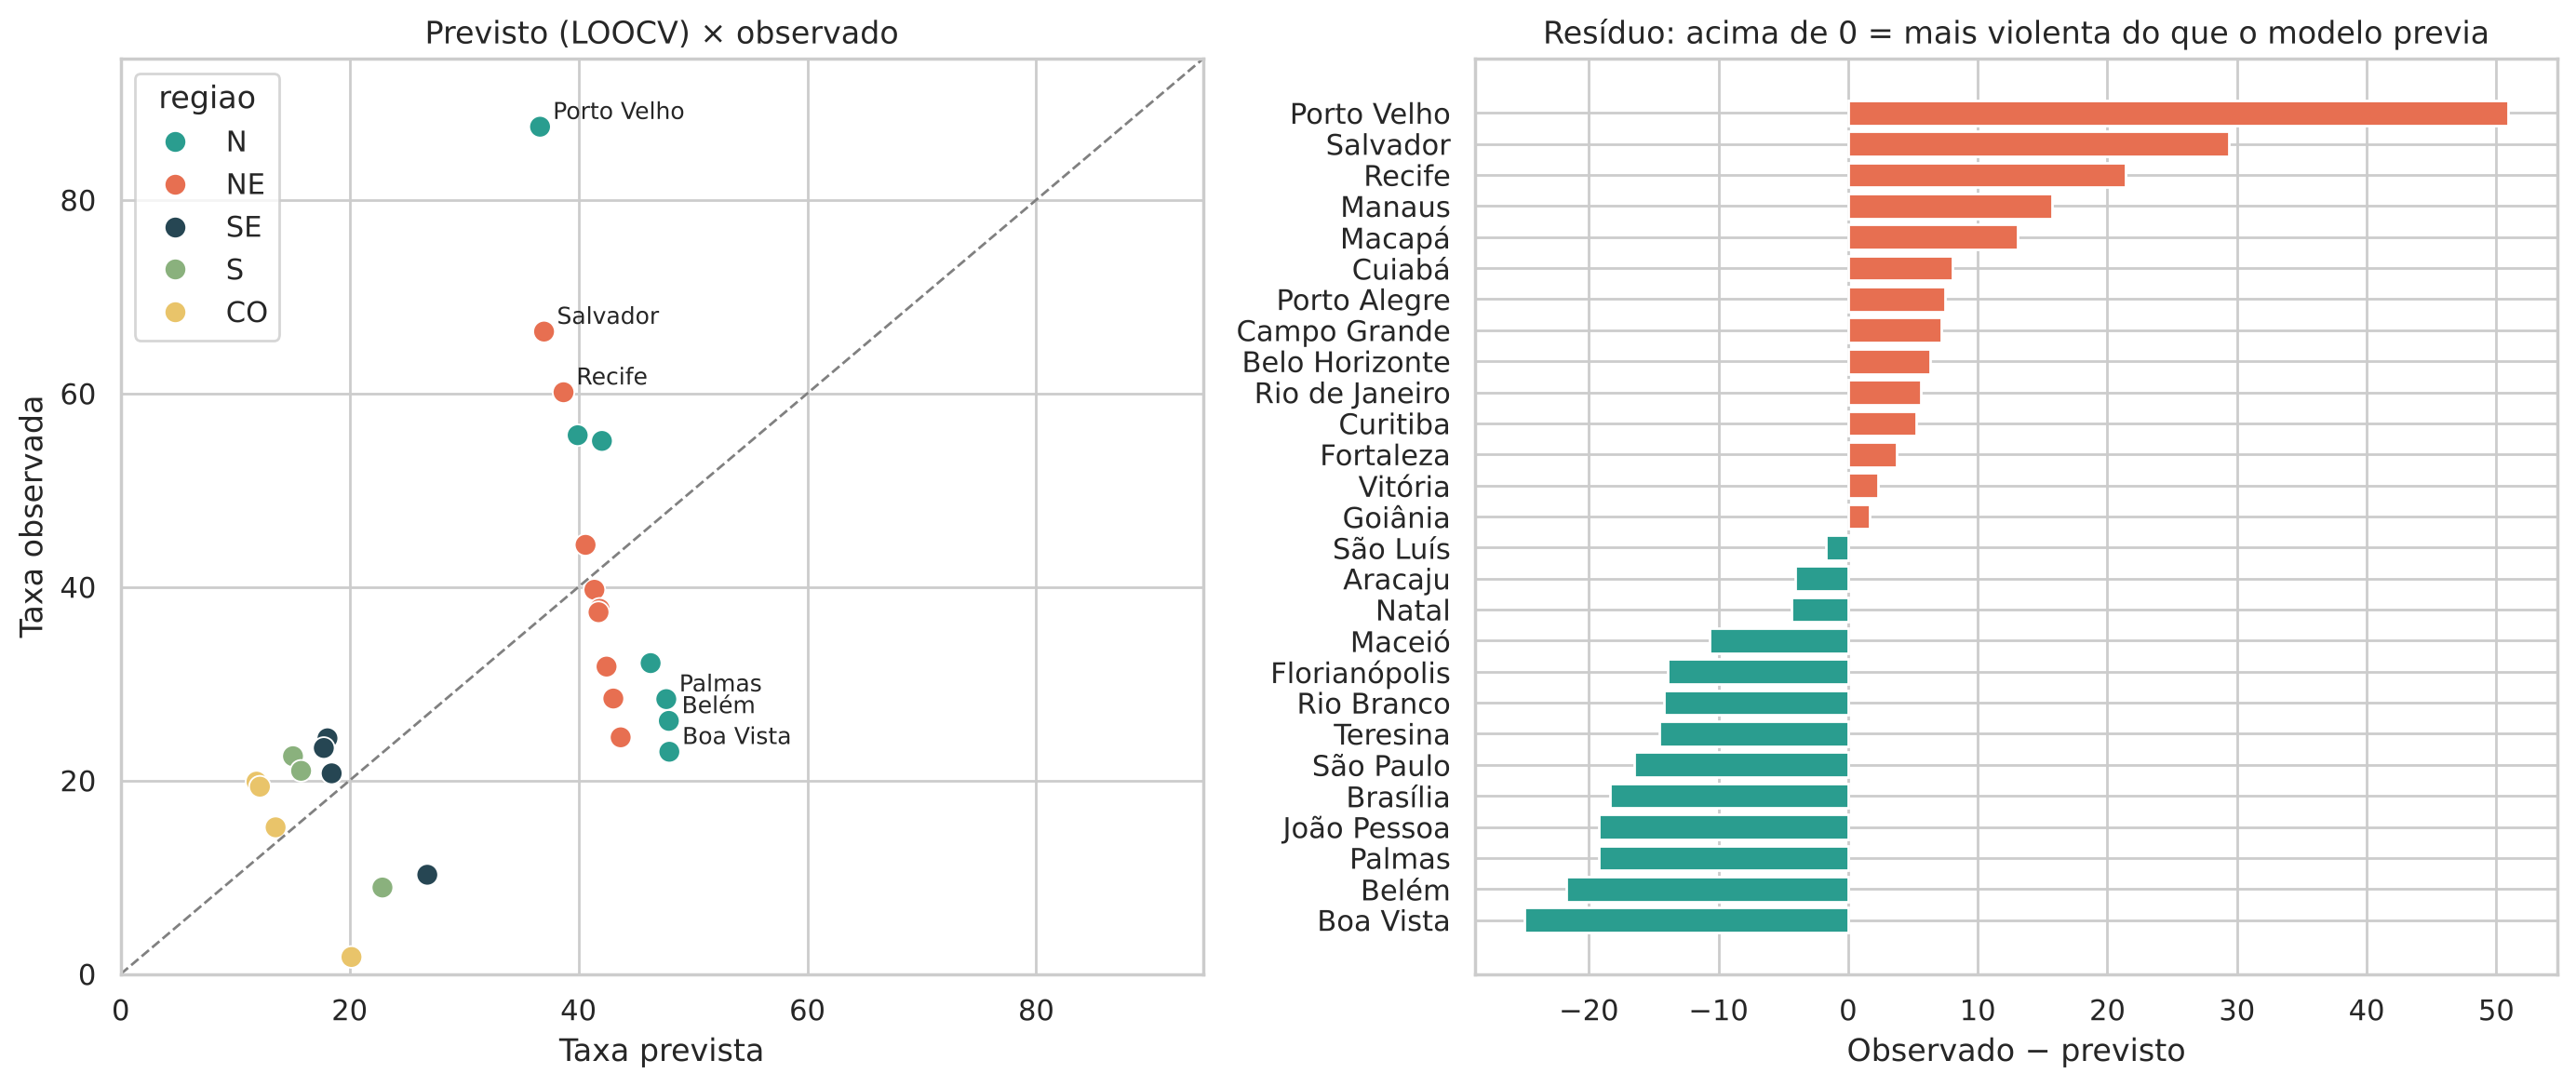

In [5]:
cv = loocv(df, "Bin. Negativa: homicídios ~ log(pop) + região")
res = df.assign(previsto=cv.predicoes, residuo=lambda d: d["taxa_calculada_100k"] - d["previsto"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lim = [0, max(res["taxa_calculada_100k"].max(), res["previsto"].max()) * 1.08]
axes[0].plot(lim, lim, ls="--", c="grey", lw=1)
sns.scatterplot(data=res, x="previsto", y="taxa_calculada_100k", hue="regiao", palette=CORES_REGIAO, s=70, ax=axes[0])
for _, r in res.loc[res["residuo"].abs().nlargest(6).index].iterrows():
    axes[0].annotate(r["municipio"], (r["previsto"], r["taxa_calculada_100k"]), xytext=(5, 3), textcoords="offset points", fontsize=9)
axes[0].set(xlim=lim, ylim=lim, title="Previsto (LOOCV) × observado", xlabel="Taxa prevista", ylabel="Taxa observada")

o = res.sort_values("residuo")
axes[1].barh(o["municipio"], o["residuo"], color=np.where(o["residuo"] > 0, "#e76f51", "#2a9d8f"))
axes[1].set(title="Resíduo: acima de 0 = mais violenta do que o modelo previa", xlabel="Observado − previsto")
plt.tight_layout(); plt.show()

**Leitura:**
- Os dois maiores erros para cima, **Porto Velho e Recife**, são capitais cuja taxa a validação marcou como inconsistente; Salvador foi marcada como outlier. Antes de sofisticar o modelo, **corrigir os dados deve render mais do que qualquer algoritmo**.
- Para baixo, o modelo superestima capitais menores do Norte (Boa Vista, Belém, Palmas): a região Norte é heterogênea, e um único coeficiente regional não basta. Variáveis socioeconômicas devem capturar melhor essa diferença.

Os resíduos são a parte mais útil para gestão pública: indicam capitais muito acima (ou abaixo) do esperado para seu porte e região, que merecem investigação qualitativa.

## Conclusões e limites

1. Com as variáveis atuais (população + região), o poder preditivo é baixo: R² fora da amostra ≈ 0,18.
2. A proposta do README (fatores socioeconômicos, policiamento, clima) **ainda não é testável** — essas variáveis não estão no dataset. Ver `SUGESTOES.md` para fontes públicas que permitem incluí-las.
3. Nenhum resultado aqui é causal. Região é um *proxy* para fatores não observados (desigualdade, disputas de facções, rotas de tráfico, investimento em segurança).
4. **Uso responsável:** modelos de "crime preditivo" podem reforçar vieses quando alimentados por dados de registro policial. Mantenha a unidade de análise agregada (município) e use os resultados para alocar políticas sociais e de prevenção, não para direcionar vigilância a pessoas ou bairros específicos.